In [1]:
import re
import numpy as np
import pandas as pd
from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.svm import LinearSVC
from scipy.sparse import hstack, csr_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate, cross_val_predict)
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

In [2]:
# Set style for EDA plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [3]:
# Load the scraped dataset
df = pd.read_csv("books_dataset.csv")

def fix_mojibake(text):
    """Undo UTF-8 text that was decoded as ISO-8859-1 during scraping ('nÃ´tre' -> 'nôtre').
    Strings that were decoded correctly fail the round trip and are returned unchanged."""
    if not isinstance(text, str):
        return text
    try:
        return text.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

text_cols = ["Title", "Description", "Category_Label"]
n_fixed = sum((df[col].apply(fix_mojibake) != df[col]).sum() for col in text_cols)
for col in text_cols:
    df[col] = df[col].apply(fix_mojibake)
print(f"Repaired encoding in {n_fixed} text fields")
print(f"Dataset Shape: {df.shape}")
df.head(3)

Repaired encoding in 2 text fields
Dataset Shape: (1000, 12)


,Book_ID,Title,Description,Category_Label,Image_Local_Path,UPC,Price_Excl_Tax,Price_Incl_Tax,Tax,Availability,Number_of_Reviews,Source_URL
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,a897fe39b1053632,£51.77,£51.77,£0.00,In stock (22 available),0,https://books.toscrape.com/catalogue/a-light-i...
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,90fa61229261140a,£53.74,£53.74,£0.00,In stock (20 available),0,https://books.toscrape.com/catalogue/tipping-t...
2,3,Soumission,"Dans une France assez proche de la nôtre, un h...",Fiction,images/3.jpg,6957f44c3847a760,£50.10,£50.10,£0.00,In stock (20 available),0,https://books.toscrape.com/catalogue/soumissio...


In [4]:
# List of irrelevant columns to drop
irrelevant_cols = [
    'UPC', 'Price_Excl_Tax', 'Price_Incl_Tax', 
    'Tax', 'Availability', 'Number_of_Reviews', 'Source_URL'
]

# Drop useless columns
df = df.drop(columns=[col for col in irrelevant_cols if col in df.columns])
df[:5]

,Book_ID,Title,Description,Category_Label,Image_Local_Path
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg
2,3,Soumission,"Dans une France assez proche de la nôtre, un h...",Fiction,images/3.jpg
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg


In [5]:
# Handle missing descriptions if any exist
df['Description'] = df['Description'].fillna('')

print("Cleaned Columns:", df.columns.tolist())
print(f"Missing values check:\n{df.isnull().sum()}")

Cleaned Columns: ['Book_ID', 'Title', 'Description', 'Category_Label', 'Image_Local_Path']
Missing values check:
Book_ID             0
Title               0
Description         0
Category_Label      0
Image_Local_Path    0
dtype: int64


In [6]:
# Map books categories into Fiction vs Non-Fiction
non_fiction_genres = {
    'Travel', 'Religion', 'Nonfiction', 'Music', 'Philosophy', 
    'Sports and Games', 'Art', 'Psychology', 'Autobiography', 
    'Parenting', 'History', 'Food and Drink', 'Business', 
    'Biography', 'Spirituality', 'Academic', 'Self Help', 
    'Health', 'Politics', 'Cultural'
}

def categorize_book(cat):
    if cat in non_fiction_genres:
        return 0  # Non-Fiction
    return 1      # Fiction

df['Is_Fiction'] = df['Category_Label'].apply(categorize_book)
df['Target_Name'] = df['Is_Fiction'].map({1: 'Fiction', 0: 'Non-Fiction'})

print(f"Class Distribution:\n{df['Target_Name'].value_counts()}")
df[:5]

Class Distribution:
Target_Name
Fiction        733
Non-Fiction    267
Name: count, dtype: int64


,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction
2,3,Soumission,"Dans une France assez proche de la nôtre, un h...",Fiction,images/3.jpg,1,Fiction
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction


In [7]:
# 1. Title character length
df['title_char_len'] = df['Title'].astype(str).apply(len)

# 2. Title word count
df['title_word_count'] = df['Title'].astype(str).apply(lambda x: len(x.split()))

# 3. Colon indicator (Non-fiction heavily relies on colons for subtitles)
df['has_subtitle_colon'] = df['Title'].astype(str).apply(lambda x: 1 if ':' in x else 0)

# 4. Description length & word count (for baseline comparison)
df['desc_char_len'] = df['Description'].apply(len)
df['desc_word_count'] = df['Description'].apply(lambda x: len(x.split()))

# Display engineered dataset preview
df[['Title', 'Target_Name', 'title_char_len', 'title_word_count', 'has_subtitle_colon']].head()

,Title,Target_Name,title_char_len,title_word_count,has_subtitle_colon
0,A Light in the Attic,Fiction,20,5,0
1,Tipping the Velvet,Fiction,18,3,0
2,Soumission,Fiction,10,1,0
3,Sharp Objects,Fiction,13,2,0
4,Sapiens: A Brief History of Humankind,Non-Fiction,37,6,1


In [8]:
# Group original Category_Label under Target_Name and count occurrences
category_breakdown = (
    df.groupby(['Target_Name', 'Category_Label'])
    .size()
    .reset_index(name='Count')
    .sort_values(by=['Target_Name', 'Count'], ascending=[True, False])
)

# Display Fiction categories
print("=== FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Fiction'].reset_index(drop=True))

print("\n=== NON-FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Non-Fiction'].reset_index(drop=True))

=== FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Fiction,Default,152
1,Fiction,Sequential Art,75
2,Fiction,Add a comment,67
3,Fiction,Fiction,65
4,Fiction,Young Adult,54
5,Fiction,Fantasy,48
6,Fiction,Romance,35
7,Fiction,Mystery,32
8,Fiction,Childrens,29
9,Fiction,Historical Fiction,26



=== NON-FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Non-Fiction,Nonfiction,110
1,Non-Fiction,Food and Drink,30
2,Non-Fiction,History,18
3,Non-Fiction,Music,13
4,Non-Fiction,Business,12
5,Non-Fiction,Philosophy,11
6,Non-Fiction,Travel,11
7,Non-Fiction,Autobiography,9
8,Non-Fiction,Art,8
9,Non-Fiction,Psychology,7


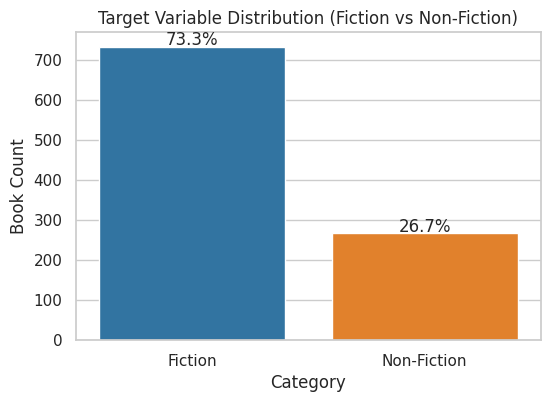

In [9]:
# Visualizing Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Target_Name', palette=['#1f77b4', '#ff7f0e'], ax=ax)
plt.title('Target Variable Distribution (Fiction vs Non-Fiction)')
plt.xlabel('Category')
plt.ylabel('Book Count')

# Show percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

In [10]:
# Remove the mixed categories entirely
categories_to_drop = ['Default', 'Add a comment']
df = df[~df['Category_Label'].isin(categories_to_drop)].copy()

# Updated Non-Fiction List
updated_non_fiction_genres = {
    'Travel', 'Religion', 'Nonfiction', 'Music', 'Philosophy', 
    'Sports and Games', 'Art', 'Psychology', 'Autobiography', 
    'Parenting', 'History', 'Food and Drink', 'Business', 
    'Biography', 'Spirituality', 'Academic', 'Self Help', 
    'Health', 'Politics', 'Cultural', 
    'Science', 'Christian', 'Crime'  # <-- Added corrections here
    # 'Historical' is NOT added: on the site it contains only two novels
    # ('All the Light We Cannot See', 'The Girl You Left Behind'), so it stays Fiction.
}

# Re-map the target variable
def categorize_book_fixed(cat):
    if cat in updated_non_fiction_genres:
        return 0  # Non-Fiction
    return 1      # Fiction

df['Is_Fiction'] = df['Category_Label'].apply(categorize_book_fixed)
df['Target_Name'] = df['Is_Fiction'].map({1: 'Fiction', 0: 'Non-Fiction'})

# Check the new, clean class distribution
print("Cleaned Dataset Shape:", df.shape)
print(f"\nNew Class Distribution:\n{df['Target_Name'].value_counts()}")
print(f"\nNew Class Percentages:\n{df['Target_Name'].value_counts(normalize=True) * 100}")
category_breakdown = (
    df.groupby(['Target_Name', 'Category_Label'])
    .size()
    .reset_index(name='Count')
    .sort_values(by=['Target_Name', 'Count'], ascending=[True, False])
)

# Display categories
print("=== FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Fiction'].reset_index(drop=True))

print("\n=== NON-FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Non-Fiction'].reset_index(drop=True))

Cleaned Dataset Shape: (781, 12)

New Class Distribution:
Target_Name
Fiction        496
Non-Fiction    285
Name: count, dtype: int64

New Class Percentages:
Target_Name
Fiction        63.508323
Non-Fiction    36.491677
Name: proportion, dtype: float64
=== FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Fiction,Sequential Art,75
1,Fiction,Fiction,65
2,Fiction,Young Adult,54
3,Fiction,Fantasy,48
4,Fiction,Romance,35
5,Fiction,Mystery,32
6,Fiction,Childrens,29
7,Fiction,Historical Fiction,26
8,Fiction,Classics,19
9,Fiction,Poetry,19



=== NON-FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Non-Fiction,Nonfiction,110
1,Non-Fiction,Food and Drink,30
2,Non-Fiction,History,18
3,Non-Fiction,Science,14
4,Non-Fiction,Music,13
5,Non-Fiction,Business,12
6,Non-Fiction,Philosophy,11
7,Non-Fiction,Travel,11
8,Non-Fiction,Autobiography,9
9,Non-Fiction,Art,8


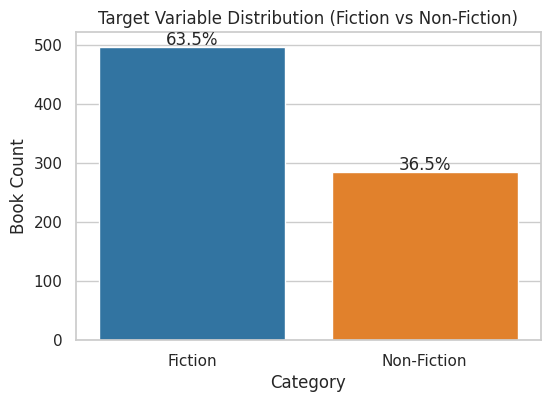

In [11]:
# Visualizing Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Target_Name', palette=['#1f77b4', '#ff7f0e'], ax=ax)
plt.title('Target Variable Distribution (Fiction vs Non-Fiction)')
plt.xlabel('Category')
plt.ylabel('Book Count')

# Show percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

In [12]:
# Group by category and inspect statistical metrics for our engineered features
feature_stats = df.groupby('Target_Name')[
    ['title_char_len', 'title_word_count', 'has_subtitle_colon', 'desc_word_count']
].agg(['mean', 'median', 'std']).round(2)

feature_stats

title_char_len               title_word_count               \
                      mean median    std             mean median   std   
Target_Name                                                              
Fiction              31.92   30.0  18.91             5.57    5.0  3.21   
Non-Fiction          54.02   52.0  30.84             9.14    9.0  4.88   

            has_subtitle_colon              desc_word_count                 
                          mean median   std            mean median     std  
Target_Name                                                                 
Fiction                   0.13    0.0  0.34          215.18  211.0   78.46  
Non-Fiction               0.66    1.0  0.47          272.18  261.0  120.22

## Description EDA

In [13]:
df.head()

,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name,title_char_len,title_word_count,has_subtitle_colon,desc_char_len,desc_word_count
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction,20,5,0,1017,164
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction,18,3,0,1029,165
2,3,Soumission,"Dans une France assez proche de la nôtre, un h...",Fiction,images/3.jpg,1,Fiction,10,1,0,1093,163
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction,13,2,0,1635,274
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction,37,6,1,1945,304


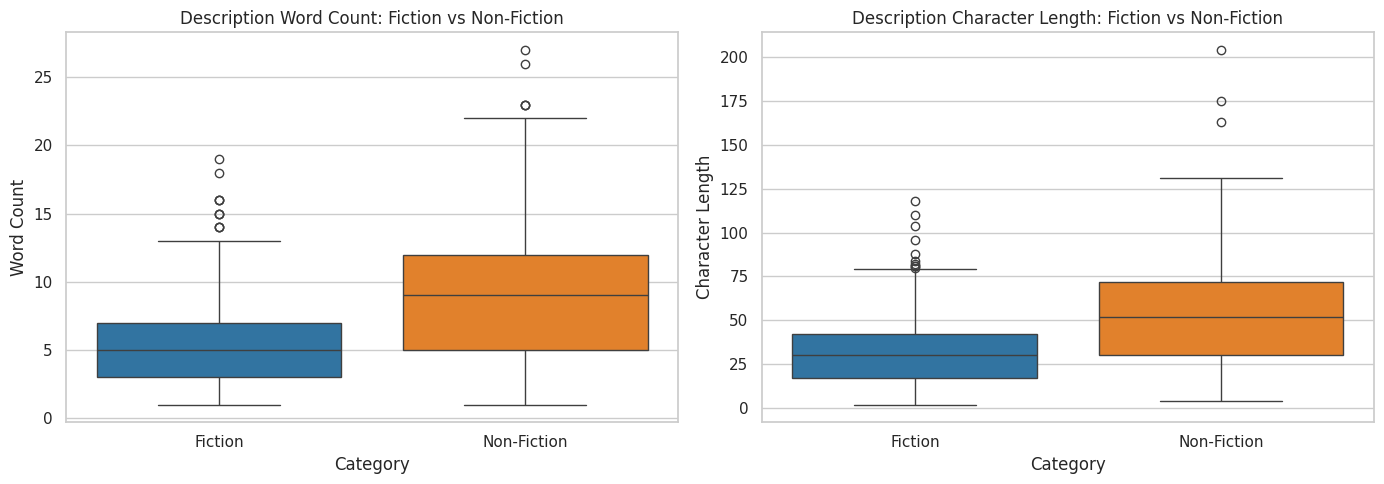

In [14]:
# Plotting title length & word count distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Target_Name', y='title_word_count', palette=['#1f77b4', '#ff7f0e'], ax=axes[0])
axes[0].set_title('Description Word Count: Fiction vs Non-Fiction')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Word Count')

sns.boxplot(data=df, x='Target_Name', y='title_char_len', palette=['#1f77b4', '#ff7f0e'], ax=axes[1])
axes[1].set_title('Description Character Length: Fiction vs Non-Fiction')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Character Length')

plt.tight_layout()
plt.show()

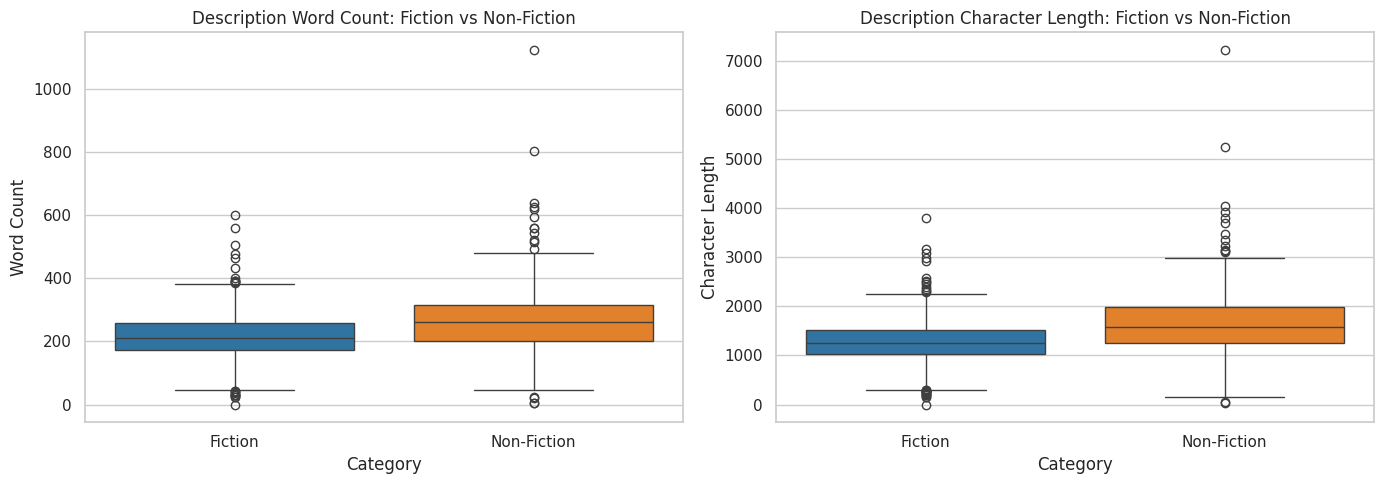

In [15]:
# Plotting description length & word count distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Target_Name', y='desc_word_count', palette=['#1f77b4', '#ff7f0e'], ax=axes[0])
axes[0].set_title('Description Word Count: Fiction vs Non-Fiction')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Word Count')

sns.boxplot(data=df, x='Target_Name', y='desc_char_len', palette=['#1f77b4', '#ff7f0e'], ax=axes[1])
axes[1].set_title('Description Character Length: Fiction vs Non-Fiction')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Character Length')

plt.tight_layout()
plt.show()

### Clean & remove stopwords

In [16]:
def clean_and_remove_stopwords(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Convert to lowercase
    text = text.lower()
    
    # 2. Replace punctuation, special characters, and digits with a space (keep only alphabets)
    #    Replacing with '' glued words together, e.g. 'midnight—with' -> 'midnightwith'
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    
    # 3. Tokenize, remove stop words, and drop tiny words (length <= 2)
    words = text.split()
    filtered_words = [
        word for word in words 
        if word not in ENGLISH_STOP_WORDS and len(word) > 2
    ]
    
    # Reassemble into a clean string
    return " ".join(filtered_words)

# Apply cleaning to the dataset
df['cleaned_description'] = df['Description'].apply(clean_and_remove_stopwords)

# Preview original vs. cleaned text
print("Comparison of Original vs Cleaned Descriptions:")
display(df[['Description', 'cleaned_description']].head(2))

Comparison of Original vs Cleaned Descriptions:


,Description,cleaned_description
0,It's hard to imagine a world without A Light i...,hard imagine world light attic classic collect...
1,"""Erotic and absorbing...Written with starling ...",erotic absorbing written starling power new yo...


In [17]:
def display_wordcloud(fiction_text, non_fiction_text, fiction_title, non_fiction_title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 15))
    
    green_dark = LinearSegmentedColormap.from_list(
        "green_dark", ["#1da100", "#2e5a28", "#1a3c1a", "#0d2010"])
    brown_dark = LinearSegmentedColormap.from_list(
        "brown_dark", ["#7a4a1e", "#9c5a22", "#c45a1a", "#e65c00"])

    # 1. Fiction Word Bubble
    wc_fiction = WordCloud(
        width=800, height=800, 
        background_color='white', 
        # color_func = lambda *args, **kwargs: "darkgreen",
        colormap=green_dark,
        max_words=100
    ).generate(fiction_text)

    axes[0].imshow(wc_fiction, interpolation='bilinear')
    axes[0].axis('off')
    axes[0].set_title(fiction_title, fontsize=16, fontweight='bold')

    # 2. Non-Fiction Word Bubble
    wc_non_fiction = WordCloud(
        width=800, height=800, 
        background_color='white', 
        colormap=brown_dark, 
        max_words=100
    ).generate(non_fiction_text)

    axes[1].imshow(wc_non_fiction, interpolation='bilinear')
    axes[1].axis('off')
    axes[1].set_title(non_fiction_title, fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.show()

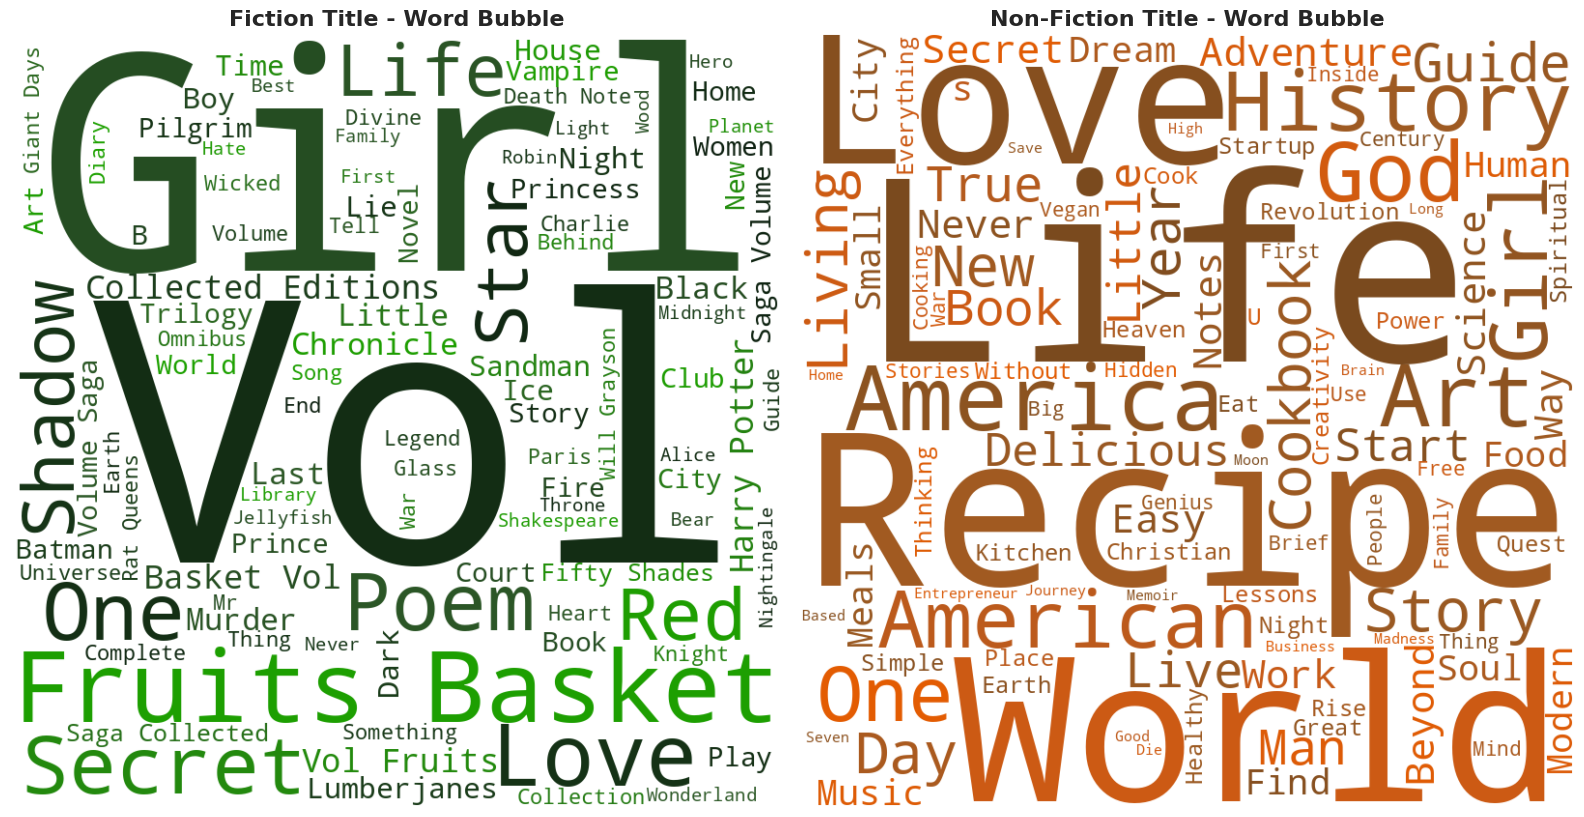

In [18]:
# Combine all cleaned text per category
fiction_title_text = " ".join(df[df['Is_Fiction'] == 1]['Title'])
non_fiction_title_text = " ".join(df[df['Is_Fiction'] == 0]['Title'])

display_wordcloud(fiction_title_text, non_fiction_title_text, 'Fiction Title - Word Bubble','Non-Fiction Title - Word Bubble' )

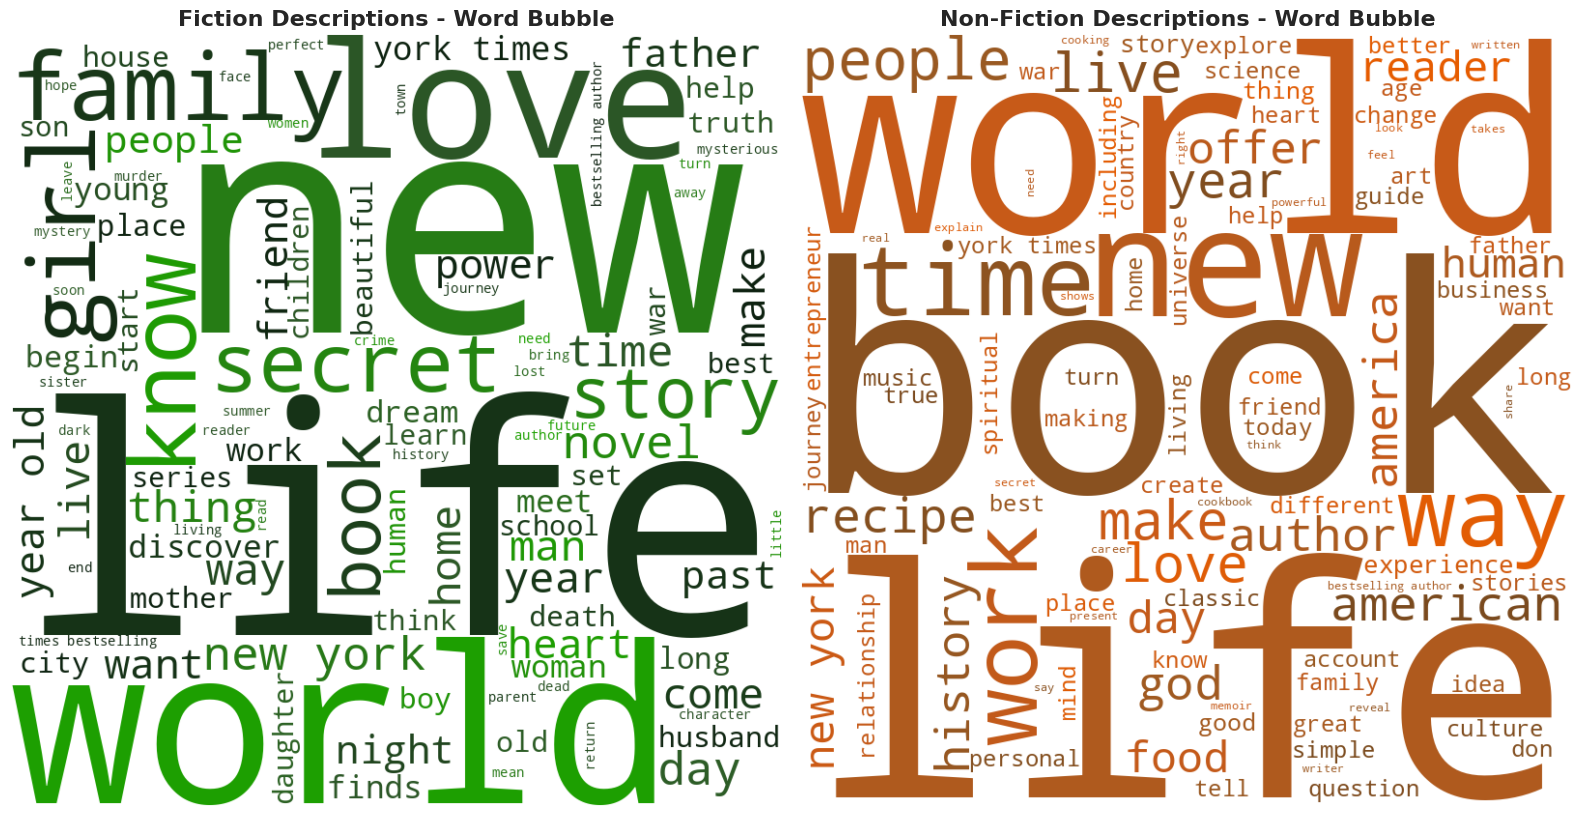

In [19]:
fiction_text = " ".join(df[df['Is_Fiction'] == 1]['cleaned_description'])
non_fiction_text = " ".join(df[df['Is_Fiction'] == 0]['cleaned_description'])

display_wordcloud(fiction_text, non_fiction_text, 'Fiction Descriptions - Word Bubble','Non-Fiction Descriptions - Word Bubble' )

### Combine title and description

In [20]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    words = text.split()
    filtered_words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(filtered_words)

df['cleaned_description'] = df['Description'].apply(clean_text)

df['cleaned_title'] = df['Title'].apply(clean_text)
df['full_text'] = df['cleaned_title'] + " " + df['cleaned_description']

print("Sample full_text entry:")
print(df['full_text'].iloc[100])

Sample full_text entry:
camp midnight ben big hero creator steven seagle returns comics new yorker magazine cartoonist jason adam katzenstein new graphic novel reluctant skye accidentally sent wrong summer camp wanting step monster skye dead set fitting won problem camp midnight exception fellow cam ben big hero creator steven seagle returns comics new yorker magazine cartoonist jason adam katzenstein new graphic novel reluctant skye accidentally sent wrong summer camp wanting step monster skye dead set fitting won problem camp midnight exception fellow camper fast friend mia fledged monster perfect book fans raina telgemeier smile wish bowls gooey eyeballs


### Vectorizing Title & Description

### Leakage-free pipeline
TF-IDF and feature scaling live inside a scikit-learn `Pipeline`, so during cross-validation they are fitted on the training folds only. The test set is held out and used exactly once, after the model has been chosen by cross-validation.

In [21]:
TEXT_COL = 'full_text'
NUM_COLS = ['title_char_len', 'title_word_count', 'has_subtitle_colon']

X = df[[TEXT_COL] + NUM_COLS]
y = df['Is_Fiction'].values

# Held-out test set: not used for any tuning or model selection
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set: {len(X_train)} books | Test set: {len(X_test)} books")


def build_pipeline(clf, max_features=1000):
    """TF-IDF on the text column + standardised title features, then the classifier."""
    features = ColumnTransformer([
        ('text', TfidfVectorizer(max_features=max_features), TEXT_COL),
        # Scaling puts title length (tens of characters) on the same footing as TF-IDF weights (0-1)
        ('num', StandardScaler(), NUM_COLS),
    ])
    return Pipeline([('features', features), ('clf', clf)])


# Same folds for every model so the comparison is fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}


def cv_summary(name, estimator, X_, y_):
    """Repeated stratified 5-fold CV (5 x 5 = 25 fits): mean and std of accuracy and macro-F1."""
    scores = cross_validate(estimator, X_, y_, cv=cv_repeated, scoring=SCORING, n_jobs=-1)
    acc, f1 = scores['test_accuracy'], scores['test_f1_macro']
    return {'Model': name,
            'CV accuracy': f"{acc.mean():.3f} ± {acc.std():.3f}",
            'CV macro-F1': f"{f1.mean():.3f} ± {f1.std():.3f}",
            'f1_mean': f1.mean()}

Training set: 624 books | Test set: 157 books


### Baseline: Logistic Regression with default settings

In [22]:
baseline = build_pipeline(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
results = [cv_summary('Baseline LR (C=1, 1000 terms)', baseline, X_train, y_train)]
pd.DataFrame(results).drop(columns='f1_mean')

,Model,CV accuracy,CV macro-F1
0,"Baseline LR (C=1, 1000 terms)",0.803 ± 0.034,0.783 ± 0.039


### Grid search & hyperparameter tuning
Scored by **macro-F1** instead of accuracy, because the classes are imbalanced (about 63% Fiction): a model that ignores Non-Fiction can still score a decent accuracy, but not a decent macro-F1. The TF-IDF vocabulary size is tuned together with the classifier.

In [23]:
grid_lr = GridSearchCV(
    build_pipeline(LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)),
    {'clf__C': [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0],
     'features__text__max_features': [500, 1000, 3000, None]},  # None = full vocabulary
    cv=cv, scoring='f1_macro', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print(f"Best Logistic Regression parameters: {grid_lr.best_params_}")
print(f"Best CV macro-F1: {grid_lr.best_score_:.3f}")

Best Logistic Regression parameters: {'clf__C': 500.0, 'features__text__max_features': 3000}
Best CV macro-F1: 0.858


In [24]:
grid_svc = GridSearchCV(
    # dual=True is required for the hinge loss
    build_pipeline(LinearSVC(class_weight='balanced', dual=True, max_iter=20000, random_state=42)),
    {'clf__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
     'clf__loss': ['hinge', 'squared_hinge'],
     'features__text__max_features': [500, 1000, 3000, None]},  # None = full vocabulary
    cv=cv, scoring='f1_macro', n_jobs=-1)
grid_svc.fit(X_train, y_train)

print(f"Best LinearSVC parameters: {grid_svc.best_params_}")
print(f"Best CV macro-F1: {grid_svc.best_score_:.3f}")

Best LinearSVC parameters: {'clf__C': 10.0, 'clf__loss': 'hinge', 'features__text__max_features': 3000}
Best CV macro-F1: 0.869


In [25]:
grid_rf = GridSearchCV(
    build_pipeline(RandomForestClassifier(class_weight='balanced', random_state=42)),
    {'clf__n_estimators': [100, 300],
     'clf__max_depth': [10, 20, None],
     'clf__min_samples_split': [2, 5],
     'features__text__max_features': [1000, 3000, None]},  # None = full vocabulary
    cv=cv, scoring='f1_macro', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print(f"Best Random Forest parameters: {grid_rf.best_params_}")
print(f"Best CV macro-F1: {grid_rf.best_score_:.3f}")

Best Random Forest parameters: {'clf__max_depth': 10, 'clf__min_samples_split': 5, 'clf__n_estimators': 300, 'features__text__max_features': None}
Best CV macro-F1: 0.856


### Model selection
Each tuned model is re-scored with repeated 5-fold CV (25 fits) on the training set, which gives a mean and a spread instead of a single noisy number. The model with the highest mean macro-F1 is selected. The test set is not looked at here.

In [26]:
tuned = {'Logistic Regression': grid_lr, 'LinearSVC': grid_svc, 'Random Forest': grid_rf}
for name, grid in tuned.items():
    results.append(cv_summary(f'{name} (tuned)', grid.best_estimator_, X_train, y_train))

results_df = pd.DataFrame(results)
display(results_df.drop(columns='f1_mean'))

best_name = max(tuned, key=lambda k: results_df.loc[results_df['Model'] == f'{k} (tuned)', 'f1_mean'].iloc[0])
final_model = tuned[best_name].best_estimator_   # GridSearchCV already refitted it on the full training set
print(f"Selected model (highest repeated-CV macro-F1): {best_name}")

,Model,CV accuracy,CV macro-F1
0,"Baseline LR (C=1, 1000 terms)",0.803 ± 0.034,0.783 ± 0.039
1,Logistic Regression (tuned),0.871 ± 0.028,0.856 ± 0.032
2,LinearSVC (tuned),0.878 ± 0.026,0.864 ± 0.030
3,Random Forest (tuned),0.869 ± 0.028,0.851 ± 0.034


Selected model (highest repeated-CV macro-F1): LinearSVC


### Final evaluation on the held-out test set
This is the only time the test set is used.

Selected model: LinearSVC
Test accuracy: 89.17% | Test macro-F1: 0.881

              precision    recall  f1-score   support

 Non-Fiction       0.88      0.81      0.84        57
     Fiction       0.90      0.94      0.92       100

    accuracy                           0.89       157
   macro avg       0.89      0.87      0.88       157
weighted avg       0.89      0.89      0.89       157



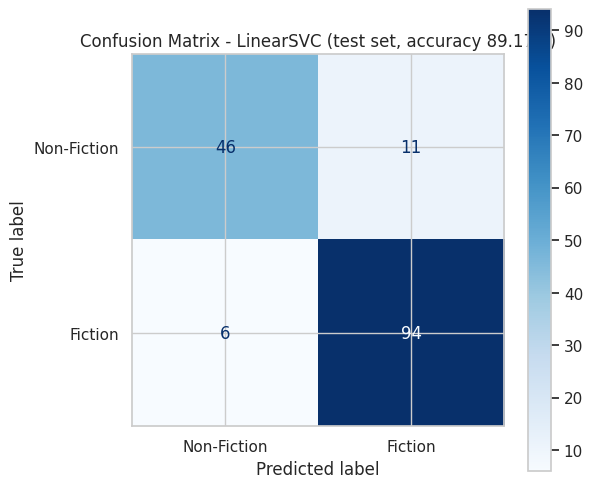

In [27]:
y_pred = final_model.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred) * 100
final_f1 = f1_score(y_test, y_pred, average='macro')

print(f"Selected model: {best_name}")
print(f"Test accuracy: {final_accuracy:.2f}% | Test macro-F1: {final_f1:.3f}\n")
print(classification_report(y_test, y_pred, target_names=['Non-Fiction', 'Fiction']))

fig, ax = plt.subplots(figsize=(6, 6))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Fiction', 'Fiction']).plot(
    cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title(f'Confusion Matrix - {best_name} (test set, accuracy {final_accuracy:.2f}%)')
plt.show()

### Coefficient analysis (tuned Logistic Regression)
The title features are standardised, so their coefficients mean "effect of one standard deviation" and can be compared roughly with the word weights.

--- TOP 10 FEATURES PUSHING TOWARDS FICTION ---
  Feature  Coefficient
    novel     9.044229
   poetry     8.479358
    poems     7.967323
      vol     6.419156
   series     5.831378
 complete     5.755022
beautiful     5.484346
    knows     5.197756
minecraft     5.170951
    finds     5.068783

--- TOP 10 FEATURES PUSHING TOWARDS NON-FICTION ---
    Feature  Coefficient
       work    -9.021440
    recipes    -8.264236
      guide    -7.729291
        say    -6.793975
    account    -6.734589
    history    -6.026400
       book    -5.946034
        god    -5.940061
translation    -5.742576
 experience    -5.617752


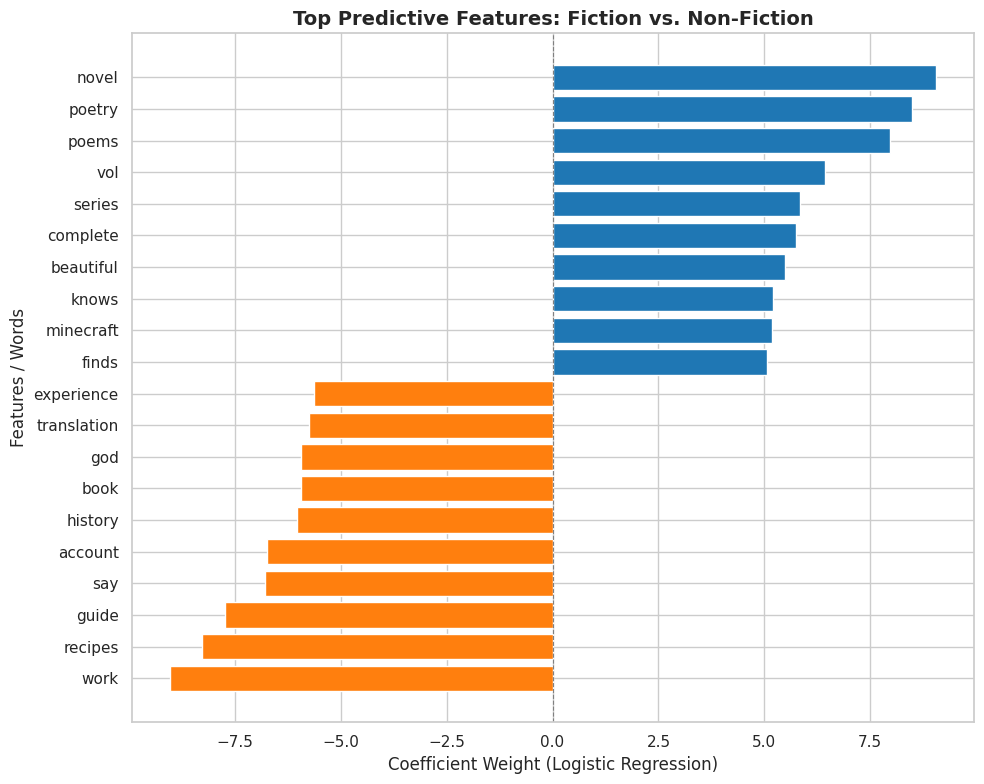

In [28]:
lr_pipe = grid_lr.best_estimator_
feature_names = [name.split('__', 1)[1] for name in lr_pipe.named_steps['features'].get_feature_names_out()]
feature_importance = pd.DataFrame({'Feature': feature_names,
                                   'Coefficient': lr_pipe.named_steps['clf'].coef_[0]})

print("--- TOP 10 FEATURES PUSHING TOWARDS FICTION ---")
print(feature_importance.nlargest(10, 'Coefficient').to_string(index=False))
print("\n--- TOP 10 FEATURES PUSHING TOWARDS NON-FICTION ---")
print(feature_importance.nsmallest(10, 'Coefficient').to_string(index=False))

top_features = pd.concat([feature_importance.nlargest(10, 'Coefficient'),
                          feature_importance.nsmallest(10, 'Coefficient')]).sort_values(by='Coefficient')

plt.figure(figsize=(10, 8))
colors = ['#ff7f0e' if v < 0 else '#1f77b4' for v in top_features['Coefficient']]
plt.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
plt.axvline(x=0, color='grey', linestyle='--', linewidth=0.8)
plt.title('Top Predictive Features: Fiction vs. Non-Fiction', fontsize=14, fontweight='bold')
plt.xlabel('Coefficient Weight (Logistic Regression)', fontsize=12)
plt.ylabel('Features / Words', fontsize=12)
plt.tight_layout()
plt.show()

## Image Feature Integration

In [29]:
df.head()

,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name,title_char_len,title_word_count,has_subtitle_colon,desc_char_len,desc_word_count,cleaned_description,cleaned_title,full_text
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction,20,5,0,1017,164,hard imagine world light attic classic collect...,light attic,light attic hard imagine world light attic cla...
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction,18,3,0,1029,165,erotic absorbing written starling power new yo...,tipping velvet,tipping velvet erotic absorbing written starli...
2,3,Soumission,"Dans une France assez proche de la nôtre, un h...",Fiction,images/3.jpg,1,Fiction,10,1,0,1093,163,dans une france assez proche tre homme engage ...,soumission,soumission dans une france assez proche tre ho...
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction,13,2,0,1635,274,wicked hipbone girl heart words like road map ...,sharp objects,sharp objects wicked hipbone girl heart words ...
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction,37,6,1,1945,304,renowned historian comes groundbreaking narrat...,sapiens brief history humankind,sapiens brief history humankind renowned histo...


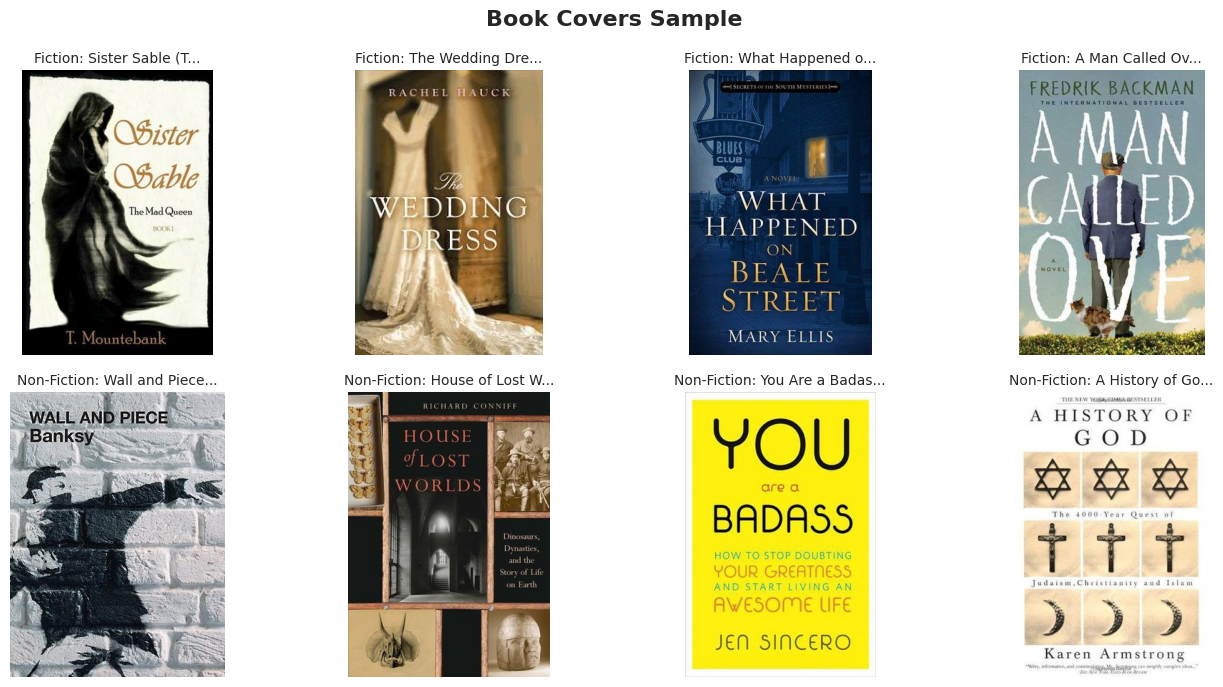

In [30]:
# Grab a random sample of 4 Fiction and 4 Non-Fiction books
fiction_samples = df[df['Is_Fiction'] == 1].sample(4, random_state=42)
non_fiction_samples = df[df['Is_Fiction'] == 0].sample(4, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, (_, row) in enumerate(fiction_samples.iterrows()):
    try:
        # Load directly from the local file path column
        img = Image.open(row['Image_Local_Path'])
        axes[0, i].imshow(img)
        axes[0, i].axis('off')
        axes[0, i].set_title(f"Fiction: {row['Title'][:15]}...", fontsize=10)
    except Exception as e:
        axes[0, i].axis('off')
        print(f"Could not load path: {row['Image_Local_Path']}")

for i, (_, row) in enumerate(non_fiction_samples.iterrows()):
    try:
        img = Image.open(row['Image_Local_Path'])
        axes[1, i].imshow(img)
        axes[1, i].axis('off')
        axes[1, i].set_title(f"Non-Fiction: {row['Title'][:15]}...", fontsize=10)
    except Exception as e:
        axes[1, i].axis('off')

plt.suptitle("Book Covers Sample", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

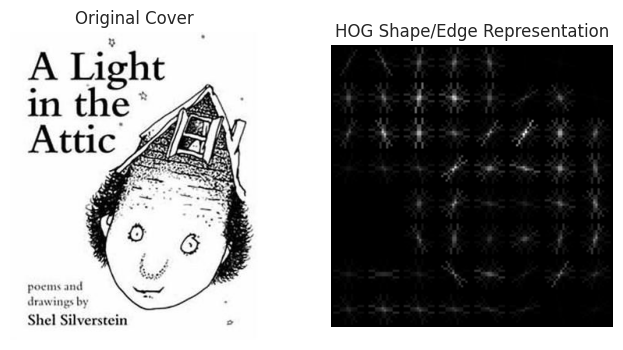

HOG feature vector length for one cover: 512


In [31]:
from skimage.feature import hog
from skimage.color import rgb2gray
from skimage.transform import resize
import tqdm

# isual Validation: Let's look at how HOG sees a book cover
sample_path = df['Image_Local_Path'].iloc[0]
img = Image.open(sample_path).convert('L') # Convert to grayscale
img_resized = img.resize((128, 128))      # Standardize size
img_array = np.array(img_resized) / 255.0

# Extract HOG features and a visual representation image
features, hog_image = hog(
    img_array, 
    orientations=8, 
    pixels_per_cell=(16, 16),
    cells_per_block=(1, 1), 
    visualize=True
)

# Plot Original vs HOG Edge Representation
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(sample_path))
axes[0].set_title("Original Cover", fontsize=12)
axes[0].axis('off')

axes[1].imshow(hog_image, cmap='gray')
axes[1].set_title("HOG Shape/Edge Representation", fontsize=12)
axes[1].axis('off')
plt.show()

print(f"HOG feature vector length for one cover: {len(features)}")

In [32]:
image_features_list = []
n_failed = 0

print("Extracting HOG layout features from local book covers...")
for path in tqdm.tqdm(df['Image_Local_Path']):
    try:
        img = Image.open(path).convert('L')
        img_resized = img.resize((128, 128))
        img_array = np.array(img_resized) / 255.0
        
        # Extract HOG features
        feats = hog(
            img_array, 
            orientations=8, 
            pixels_per_cell=(16, 16),
            cells_per_block=(1, 1), 
            visualize=False
        )
        image_features_list.append(feats)
    except Exception:
        # Fallback for missing or corrupted images
        image_features_list.append(np.zeros(512)) # 512 is standard for this HOG config
        n_failed += 1

X_image_features = np.array(image_features_list)
print(f"Final Image Feature Matrix Shape: {X_image_features.shape}")
print(f"Covers that could not be read (zero vector used): {n_failed}")

Extracting HOG layout features from local book covers...


  0%|          | 0/781 [00:00<?, ?it/s]

  3%|▎         | 21/781 [00:00<00:03, 208.89it/s]

  6%|▌         | 43/781 [00:00<00:03, 211.11it/s]

  8%|▊         | 65/781 [00:00<00:03, 205.17it/s]

...

 92%|█████████▏| 719/781 [00:03<00:00, 239.75it/s]

 95%|█████████▌| 744/781 [00:03<00:00, 233.11it/s]

 98%|█████████▊| 768/781 [00:03<00:00, 213.78it/s]

100%|██████████| 781/781 [00:03<00:00, 231.74it/s]

Final Image Feature Matrix Shape: (781, 512)
Covers that could not be read (zero vector used): 0


In [33]:
# Fair comparison: same training split, same CV folds and the same tuned classifier as the text model.
# The 512 HOG values are standardised like the title features (the earlier run left them unscaled
# and used C=0.1 instead of the tuned value).
hog_cols = [f'hog_{i}' for i in range(X_image_features.shape[1])]
X_all = pd.concat([X, pd.DataFrame(X_image_features, index=df.index, columns=hog_cols)], axis=1)
X_train_m = X_all.loc[X_train.index]   # identical rows to the text-only training set

best_max_features = final_model.get_params()['features__text__max_features']
multimodal = Pipeline([
    ('features', ColumnTransformer([
        ('text', TfidfVectorizer(max_features=best_max_features), TEXT_COL),
        ('num', StandardScaler(), NUM_COLS),
        ('img', StandardScaler(), hog_cols),
    ])),
    ('clf', clone(final_model.named_steps['clf'])),
])

image_results = [
    cv_summary(f'{best_name}: text + title features', clone(final_model), X_train, y_train),
    cv_summary(f'{best_name}: text + title + HOG', multimodal, X_train_m, y_train),
]
pd.DataFrame(image_results).drop(columns='f1_mean')

,Model,CV accuracy,CV macro-F1
0,LinearSVC: text + title features,0.878 ± 0.026,0.864 ± 0.030
1,LinearSVC: text + title + HOG,0.633 ± 0.035,0.610 ± 0.036


### Image features, revisited
The raw HOG experiment above gives the image block 512 standardised columns next to roughly 3,000 sparse TF-IDF columns, so the classifier can easily fit noise in the images. Three questions are tested here:

1. **Do covers carry any signal on their own?** Image-only models are compared with a majority-class baseline.
2. **Does compressing HOG help?** PCA keeps only the strongest shape/layout directions (the number of components is tuned).
3. **Is colour more useful than shape?** A 48-value HSV colour histogram (16 bins each for hue, saturation and brightness) is a much smaller and simpler cover descriptor than HOG.

All models use the same training split and the same repeated 5-fold CV as the text models.

In [34]:
def colour_histogram(path, bins=16):
    """Hue, saturation and value histograms of a cover, each normalised to sum to 1."""
    hsv = np.asarray(Image.open(path).convert('RGB').resize((128, 128)).convert('HSV'))
    hists = [np.histogram(hsv[..., ch], bins=bins, range=(0, 256))[0] for ch in range(3)]
    return np.concatenate([h / h.sum() for h in hists])

X_colour = np.array([colour_histogram(p) for p in df['Image_Local_Path']])
colour_cols = [f'colour_{i}' for i in range(X_colour.shape[1])]
X_all = pd.concat([X_all, pd.DataFrame(X_colour, index=df.index, columns=colour_cols)], axis=1)
X_train_all = X_all.loc[X_train.index]
print(f"Colour feature matrix: {X_colour.shape}")

Colour feature matrix: (781, 48)


In [35]:
def image_pipeline(cols, clf, pca=False, with_text=False):
    """Image columns (standardised, optionally PCA-compressed), optionally next to the text features."""
    img_steps = [('scale', StandardScaler())] + ([('pca', PCA(random_state=42))] if pca else [])
    blocks = [('img', Pipeline(img_steps), cols)]
    if with_text:
        blocks = [('text', TfidfVectorizer(max_features=best_max_features), TEXT_COL),
                  ('num', StandardScaler(), NUM_COLS)] + blocks
    return Pipeline([('features', ColumnTransformer(blocks)), ('clf', clf)])


def tune(pipe, grid):
    search = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1).fit(X_train_all, y_train)
    return search.best_estimator_, search.best_params_


lr_img = LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)
svc = clone(final_model.named_steps['clf'])
pca_grid = {'features__img__pca__n_components': [5, 10, 20, 50]}

experiments = {
    'Image only: HOG + PCA (LR)':
        tune(image_pipeline(hog_cols, lr_img, pca=True), {**pca_grid, 'clf__C': [0.01, 0.1, 1.0]}),
    'Image only: colour histogram (LR)':
        tune(image_pipeline(colour_cols, lr_img), {'clf__C': [0.01, 0.1, 1.0]}),
    f'{best_name}: text + title + HOG/PCA':
        tune(image_pipeline(hog_cols, svc, pca=True, with_text=True), {**pca_grid, 'clf__C': [0.1, 1.0, 10.0]}),
    f'{best_name}: text + title + colour':
        tune(image_pipeline(colour_cols, svc, with_text=True), {'clf__C': [0.1, 1.0, 10.0]}),
}

image_table = [cv_summary('Majority-class baseline (always Fiction)',
                          DummyClassifier(strategy='most_frequent'), X_train, y_train)]
for name, (estimator, params) in experiments.items():
    row = cv_summary(name, estimator, X_train_all, y_train)
    row['Chosen parameters'] = ', '.join(f"{k.split('__')[-1]}={v}" for k, v in params.items())
    image_table.append(row)
image_table += image_results   # text-only and raw-HOG rows from the cell above

pd.DataFrame(image_table).drop(columns='f1_mean')

,Model,CV accuracy,CV macro-F1,Chosen parameters
0,Majority-class baseline (always Fiction),0.635 ± 0.003,0.388 ± 0.001,NaN
1,Image only: HOG + PCA (LR),0.646 ± 0.036,0.621 ± 0.041,"C=0.1, n_components=5"
2,Image only: colour histogram (LR),0.573 ± 0.046,0.558 ± 0.046,C=0.01
3,LinearSVC: text + title + HOG/PCA,0.890 ± 0.025,0.878 ± 0.028,"C=10.0, n_components=10"
4,LinearSVC: text + title + colour,0.850 ± 0.028,0.833 ± 0.033,C=10.0
5,LinearSVC: text + title features,0.878 ± 0.026,0.864 ± 0.030,NaN
6,LinearSVC: text + title + HOG,0.633 ± 0.035,0.610 ± 0.036,NaN


Is the gain from HOG/PCA real? Both models were scored on exactly the same 25 train/validation folds, so they can be compared fold by fold (a paired comparison) instead of only by their means.

In [36]:
fused_model = experiments[f'{best_name}: text + title + HOG/PCA'][0]
f1_text = cross_validate(clone(final_model), X_train_all, y_train, cv=cv_repeated, scoring='f1_macro', n_jobs=-1)['test_score']
f1_fused = cross_validate(clone(fused_model), X_train_all, y_train, cv=cv_repeated, scoring='f1_macro', n_jobs=-1)['test_score']
diff = f1_fused - f1_text
print(f"Macro-F1, text only:        {f1_text.mean():.3f}")
print(f"Macro-F1, text + HOG/PCA:   {f1_fused.mean():.3f}")
print(f"Mean paired difference:     {diff.mean():+.3f} (std {diff.std():.3f})")
print(f"HOG/PCA better on {(diff > 0).sum()} of {len(diff)} folds, worse on {(diff < 0).sum()}, tied on {(diff == 0).sum()}")

Macro-F1, text only:        0.864
Macro-F1, text + HOG/PCA:   0.878
Mean paired difference:     +0.014 (std 0.022)
HOG/PCA better on 18 of 25 folds, worse on 6, tied on 1


## Literal reading of the task: only the site's *Fiction* and *Nonfiction* categories
The brief says to focus on "two categories: Fiction and Nonfiction". The main experiments map all 50 site categories to the two classes, which gives 781 labelled books. The site also has two categories literally named *Fiction* and *Nonfiction*. They are checked here in two ways:

* **(a)** the same model, cross-validated on those 175 books alone;
* **(b)** a transfer test: train on the other 606 books (the broad mapping) and predict the 175, which the model has never seen.

In [37]:
subset_mask = df['Category_Label'].isin(['Fiction', 'Nonfiction']).values
X_sub, y_sub = X[subset_mask], y[subset_mask]
print(f"Subset: {subset_mask.sum()} books ({(y_sub == 1).sum()} Fiction, {(y_sub == 0).sum()} Nonfiction)\n")

# (a) cross-validation on the subset alone (same hyperparameters as the selected model)
display(pd.DataFrame([
    cv_summary('Majority-class baseline', DummyClassifier(strategy='most_frequent'), X_sub, y_sub),
    cv_summary(f'{best_name}, CV on the 175 books', clone(final_model), X_sub, y_sub),
]).drop(columns='f1_mean'))

# (b) transfer: train on the 606 broadly-mapped books, test on the 175
transfer_model = clone(final_model).fit(X[~subset_mask], y[~subset_mask])
y_sub_pred = transfer_model.predict(X_sub)
print(f"\n(b) Trained on the other {(~subset_mask).sum()} books, tested on the 175: "
      f"accuracy {accuracy_score(y_sub, y_sub_pred):.3f}, macro-F1 {f1_score(y_sub, y_sub_pred, average='macro'):.3f}\n")
print(classification_report(y_sub, y_sub_pred, target_names=['Non-Fiction', 'Fiction']))

Subset: 175 books (65 Fiction, 110 Nonfiction)



,Model,CV accuracy,CV macro-F1
0,Majority-class baseline,0.629 ± 0.000,0.386 ± 0.000
1,"LinearSVC, CV on the 175 books",0.850 ± 0.071,0.847 ± 0.070



(b) Trained on the other 606 books, tested on the 175: accuracy 0.771, macro-F1 0.771

              precision    recall  f1-score   support

 Non-Fiction       0.97      0.65      0.78       110
     Fiction       0.62      0.97      0.76        65

    accuracy                           0.77       175
   macro avg       0.80      0.81      0.77       175
weighted avg       0.84      0.77      0.77       175



## Error analysis
Which books does the selected model get wrong? Out-of-fold predictions (5-fold CV over all 781 books, using the selected model's hyperparameters) give every book a prediction from a model that did not train on it, which is enough data to compare error rates between the original site categories. The hyperparameters were chosen on the training split, so these numbers are slightly optimistic for the 157 test books; the held-out test set below is the honest check.

In [38]:
oof_pred = cross_val_predict(clone(final_model), X, y, cv=cv, n_jobs=-1)
errors = df[['Title', 'Category_Label', 'Target_Name']].assign(wrong=(oof_pred != y))
print(f"Out-of-fold accuracy over all 781 books: {1 - errors['wrong'].mean():.3f}\n")

by_category = (errors.groupby('Category_Label')
               .agg(Class=('Target_Name', 'first'), Books=('wrong', 'size'), Errors=('wrong', 'sum')))
by_category['Error rate'] = (by_category['Errors'] / by_category['Books']).round(2)
print("Categories with at least 5 books, highest error rate first:")
by_category[by_category['Books'] >= 5].sort_values(['Error rate', 'Books'], ascending=False)

Out-of-fold accuracy over all 781 books: 0.892

Categories with at least 5 books, highest error rate first:


,Class,Books,Errors,Error rate
Category_Label,,,,
Sports and Games,Non-Fiction,5,4,0.80
Travel,Non-Fiction,11,5,0.45
Humor,Fiction,10,4,0.40
Music,Non-Fiction,13,5,0.38
Autobiography,Non-Fiction,9,3,0.33
Philosophy,Non-Fiction,11,3,0.27
Art,Non-Fiction,8,2,0.25
Childrens,Fiction,29,6,0.21
Nonfiction,Non-Fiction,110,22,0.20


In [39]:
# Every misclassified book in the held-out test set
test_pred = final_model.predict(X_test)
label_name = {1: 'Fiction', 0: 'Non-Fiction'}
test_errors = (df.loc[X_test.index, ['Title', 'Category_Label', 'Target_Name']]
               .assign(Predicted=[label_name[p] for p in test_pred])
               .loc[test_pred != y_test])
test_errors['Title'] = test_errors['Title'].str.slice(0, 70)
print(f"{len(test_errors)} of {len(y_test)} test books misclassified")
test_errors.sort_values('Target_Name')

17 of 157 test books misclassified


,Title,Category_Label,Target_Name,Predicted
851,Do Androids Dream of Electric Sheep? (Blade Ru...,Science Fiction,Fiction,Non-Fiction
497,Toddlers Are A**holes: It's Not Your Fault,Humor,Fiction,Non-Fiction
298,"Hyperbole and a Half: Unfortunate Situations, ...",Humor,Fiction,Non-Fiction
921,"The Sandman, Vol. 1: Preludes and Nocturnes (T...",Sequential Art,Fiction,Non-Fiction
186,I Had a Nice Time And Other Lies...: How to fi...,Womens Fiction,Fiction,Non-Fiction
963,Of Mice and Men,Classics,Fiction,Non-Fiction
66,The Gutsy Girl: Escapades for Your Life of Epi...,Nonfiction,Non-Fiction,Fiction
41,Reasons to Stay Alive,Nonfiction,Non-Fiction,Fiction
28,Worlds Elsewhere: Journeys Around Shakespeare’...,Nonfiction,Non-Fiction,Fiction
594,The Hiding Place,History,Non-Fiction,Fiction
